In [1]:
#Data cleaning documented

In [2]:
import pandas as pd
import json
import numpy as np

In [3]:
df=pd.read_json("/Users/aldozamora/Downloads/aruba_readings_con_consumo_oficial.json")
df


,id,station_id,timestamp,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index,consumo_kw
0,ccdcf0e5-6ca1-4d82-bc25-0881de96dc7c,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:00:00+00:00,32.4,68.9,23.1,45.7,1013.2,0.0,11.8,0.0,166603.53
1,7b432baa-8447-49bd-8745-f6bce07b2aa5,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:05:00+00:00,32.4,68.9,23.1,45.3,1013.2,0.0,12.1,0.0,167020.52
2,df2d0bbd-8384-4467-8b77-aefd811a1a3f,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:10:00+00:00,32.6,68.7,23.0,44.8,1013.2,0.0,11.8,0.0,167610.95
3,0d7a67f8-f725-426f-b905-220fb4d987fa,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:15:00+00:00,32.6,68.6,23.0,45.3,1013.2,0.0,11.8,0.0,168100.81
4,939fdce1-c965-4452-b614-25144385ed55,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:20:00+00:00,32.8,68.6,22.8,45.1,1013.2,0.0,12.5,0.0,168357.15
...,...,...,...,...,...,...,...,...,...,...,...,...
1351003,906080de-32b2-417b-9dfe-5eb761b0ffeb,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:35:00+00:00,28.4,72.0,31.4,53.5,1012.9,0.0,12.5,0.0,106043.88
1351004,5c5d65dd-abc0-4753-8a56-551e69e6c8ff,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:40:00+00:00,28.3,71.7,31.2,52.9,1012.9,0.0,11.7,0.0,106638.10
1351005,e891ed47-f67a-46a2-9189-091e9735d1ab,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:45:00+00:00,28.4,71.4,31.1,52.9,1012.9,0.0,11.7,0.0,107508.21
1351006,d08716f6-bfb3-4efd-bb62-8a1e0363607f,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:50:00+00:00,28.5,71.1,31.2,53.3,1012.9,0.0,12.0,0.0,108113.22


In [4]:
df.tail()

,id,station_id,timestamp,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index,consumo_kw
1351003,906080de-32b2-417b-9dfe-5eb761b0ffeb,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:35:00+00:00,28.4,72.0,31.4,53.5,1012.9,0.0,12.5,0.0,106043.88
1351004,5c5d65dd-abc0-4753-8a56-551e69e6c8ff,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:40:00+00:00,28.3,71.7,31.2,52.9,1012.9,0.0,11.7,0.0,106638.10
1351005,e891ed47-f67a-46a2-9189-091e9735d1ab,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:45:00+00:00,28.4,71.4,31.1,52.9,1012.9,0.0,11.7,0.0,107508.21
1351006,d08716f6-bfb3-4efd-bb62-8a1e0363607f,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:50:00+00:00,28.5,71.1,31.2,53.3,1012.9,0.0,12.0,0.0,108113.22
1351007,e5af1cbe-7326-4e52-97fa-86b99a05a000,f678bd98-07d3-459d-bd4d-7aaba7051847,2026-09-17 21:55:00+00:00,28.7,70.9,31.3,52.9,1012.9,0.0,11.5,0.0,109011.26


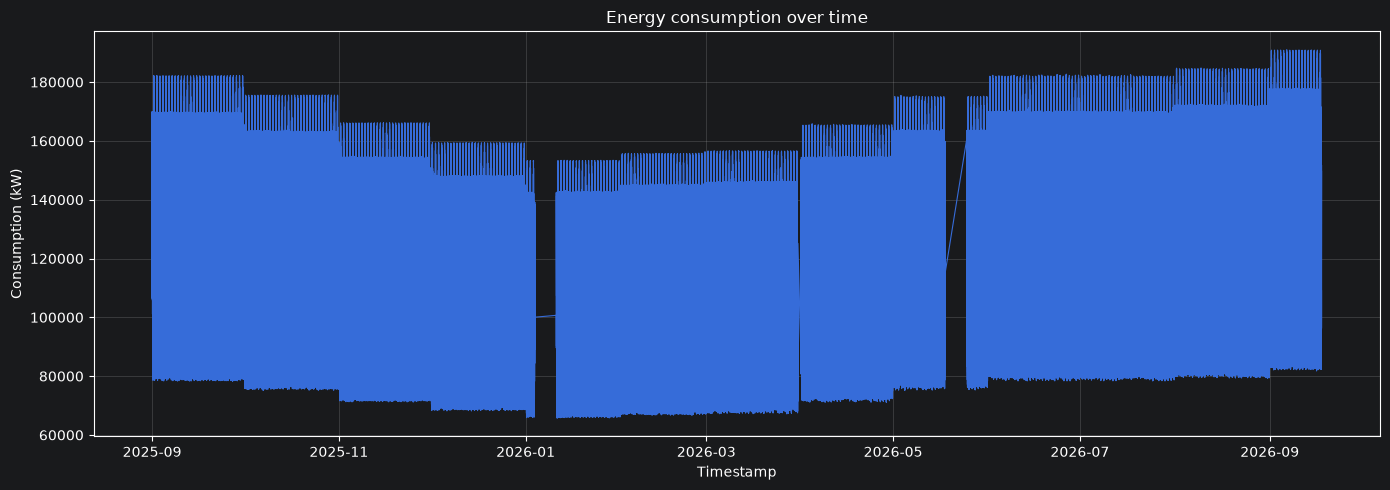

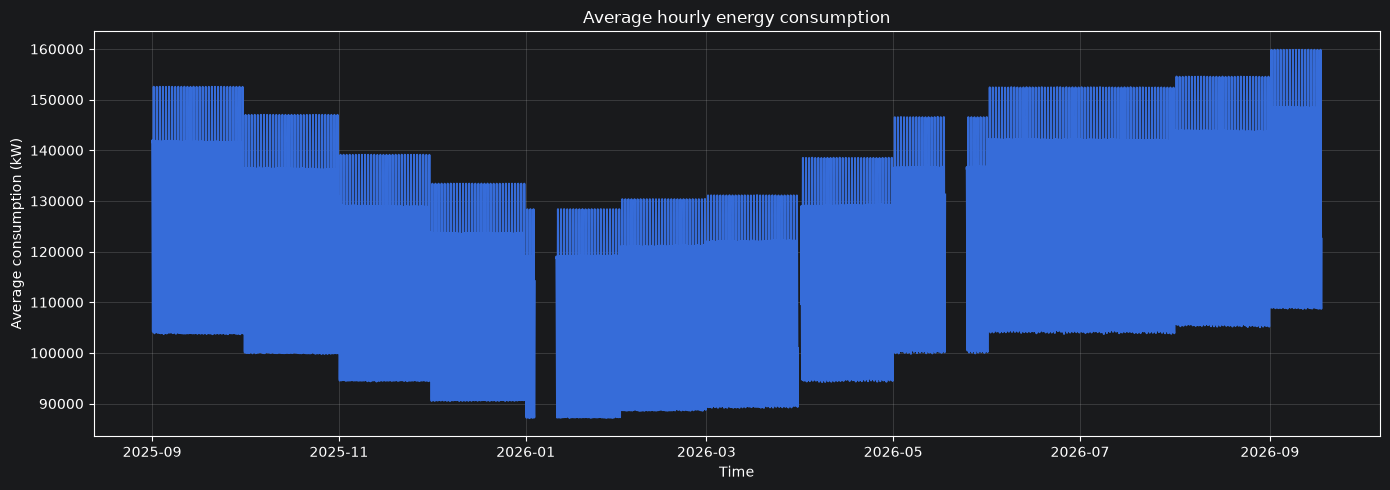

In [5]:
import matplotlib.pyplot as plt

#
# Convert and sort timestamps
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp")

# Convert columns to NumPy arrays
time = df["timestamp"].to_numpy()
consumption = df["consumo_kw"].to_numpy(dtype=float)

# Plot
plt.figure(figsize=(14, 5))
plt.plot(time, consumption, linewidth=0.8)

plt.title("Energy consumption over time")
plt.xlabel("Timestamp")
plt.ylabel("Consumption (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp")

hourly = df["consumo_kw"].resample("1h").mean()

x = hourly.index.to_numpy()
y = hourly.to_numpy(dtype=float)

plt.figure(figsize=(14, 5))
plt.plot(x, y)
plt.title("Average hourly energy consumption")
plt.xlabel("Time")
plt.ylabel("Average consumption (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
df = df.reset_index()


In [7]:
with open("/Users/aldozamora/Downloads/aruba_readings_con_consumo_oficial.json") as f:
    raw = json.load(f)

df2 = pd.DataFrame(raw)
print("Rows before:", len(df2))

# every column except id
cols = [c for c in df2.columns if c != "id"]

# keep the first reading, drop later ones with identical values
df_clean = df2.drop_duplicates(subset=cols, keep="first")

print("Rows after:", len(df_clean))
print("Duplicates removed:", len(df2) - len(df_clean))

Rows before: 1351008
Rows after: 1351007
Duplicates removed: 1


In [8]:
df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

is_dup = (df[cols] == df[cols].shift()).all(axis=1)
df_clean = df[~is_dup]

In [9]:
df[df.duplicated(subset=cols, keep=False)].sort_values(["station_id", "timestamp"]).head(10)

,timestamp,id,station_id,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index,consumo_kw
411462,2026-05-11 22:15:00+00:00,ad134e66-7665-466c-b666-2f0e71059a90,82a31d3a-9895-42e5-8ea0-11e8cb15b964,31.2,71.4,21.0,46.2,1015.7,0.0,12.3,0.0,92325.18
411463,2026-05-11 22:15:00+00:00,9bd36d21-2a26-49b5-a118-0ea10007d1dc,82a31d3a-9895-42e5-8ea0-11e8cb15b964,31.2,71.4,21.0,46.2,1015.7,0.0,12.3,0.0,92325.18


In [10]:
df

,timestamp,id,station_id,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index,consumo_kw
0,2025-09-01 00:00:00+00:00,ccdcf0e5-6ca1-4d82-bc25-0881de96dc7c,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.4,68.9,23.1,45.7,1013.2,0.0,11.8,0.0,166603.53
1,2025-09-01 00:05:00+00:00,7b432baa-8447-49bd-8745-f6bce07b2aa5,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.4,68.9,23.1,45.3,1013.2,0.0,12.1,0.0,167020.52
2,2025-09-01 00:10:00+00:00,df2d0bbd-8384-4467-8b77-aefd811a1a3f,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.6,68.7,23.0,44.8,1013.2,0.0,11.8,0.0,167610.95
3,2025-09-01 00:15:00+00:00,0d7a67f8-f725-426f-b905-220fb4d987fa,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.6,68.6,23.0,45.3,1013.2,0.0,11.8,0.0,168100.81
4,2025-09-01 00:20:00+00:00,939fdce1-c965-4452-b614-25144385ed55,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.8,68.6,22.8,45.1,1013.2,0.0,12.5,0.0,168357.15
...,...,...,...,...,...,...,...,...,...,...,...,...
1351003,2026-09-17 21:35:00+00:00,906080de-32b2-417b-9dfe-5eb761b0ffeb,f678bd98-07d3-459d-bd4d-7aaba7051847,28.4,72.0,31.4,53.5,1012.9,0.0,12.5,0.0,106043.88
1351004,2026-09-17 21:40:00+00:00,5c5d65dd-abc0-4753-8a56-551e69e6c8ff,f678bd98-07d3-459d-bd4d-7aaba7051847,28.3,71.7,31.2,52.9,1012.9,0.0,11.7,0.0,106638.10
1351005,2026-09-17 21:45:00+00:00,e891ed47-f67a-46a2-9189-091e9735d1ab,f678bd98-07d3-459d-bd4d-7aaba7051847,28.4,71.4,31.1,52.9,1012.9,0.0,11.7,0.0,107508.21
1351006,2026-09-17 21:50:00+00:00,d08716f6-bfb3-4efd-bb62-8a1e0363607f,f678bd98-07d3-459d-bd4d-7aaba7051847,28.5,71.1,31.2,53.3,1012.9,0.0,12.0,0.0,108113.22


In [11]:
numeric_cols = [
    "temperature_c", "humidity_pct", "wind_speed_kmh",
    "wind_direction_deg", "pressure_hpa", "precipitation_mm",
    "visibility_km", "uv_index", "consumo_kw"
]

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

In [12]:
key = ["station_id", "timestamp"]

duplicate_rows = df[df.duplicated(key, keep=False)]
conflicting_keys = (
    duplicate_rows.groupby(key)
    .size()
    .loc[lambda s: s > 1]
)

In [13]:
df = df.sort_values(["station_id", "timestamp"])

expected_interval = pd.Timedelta(minutes=5)
df["interval"] = df.groupby("station_id")["timestamp"].diff()

gaps = df[df["interval"] > expected_interval]
irregular_readings = df[
    df["interval"].notna() & (df["interval"] != expected_interval)
]

In [14]:
valid = (
    df["humidity_pct"].between(0, 100)
    & df["wind_speed_kmh"].ge(0)
    & df["wind_direction_deg"].between(0, 360)
    & df["pressure_hpa"].between(850, 1100)
    & df["precipitation_mm"].ge(0)
    & df["visibility_km"].ge(0)
    & df["uv_index"].between(0, 15)
    & df["consumo_kw"].ge(0)
)

In [15]:
for col in numeric_cols:
    df[f"{col}_change"] = df.groupby("station_id")[col].diff()

In [16]:
df["temperature_repeated"] = (
    df.groupby("station_id")["temperature_c"]
      .transform(lambda s: s.rolling(12).apply(
          lambda x: x.nunique() == 1, raw=False
      ))
)

In [17]:
df = df.sort_values(["station_id", "timestamp"])

df["consumo_intervalo"] = (
    df.groupby("station_id")["consumo_kw"].diff()
)

negative_resets = df["consumo_intervalo"] < 0

In [18]:
df["quality_flag"] = "valid"
df.loc[~valid, "quality_flag"] = "invalid_range"
df.loc[df["interval"] > expected_interval, "quality_flag"] = "gap_after_previous"

In [19]:
df = df.sort_values("timestamp")

train = df[df["timestamp"] < "2026-07-01"]
test = df[df["timestamp"] >= "2026-07-01"]

In [20]:
report = {
    "rows_original": len(df),
    "missing_timestamps": df["timestamp"].isna().sum(),
    "duplicate_station_timestamp": df.duplicated(
        ["station_id", "timestamp"]
    ).sum(),
    "invalid_range": (~valid).sum(),
    "missing_values": df[numeric_cols].isna().sum().to_dict(),
}

In [21]:
df

,timestamp,id,station_id,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,...,wind_speed_kmh_change,wind_direction_deg_change,pressure_hpa_change,precipitation_mm_change,visibility_km_change,uv_index_change,consumo_kw_change,temperature_repeated,consumo_intervalo,quality_flag
0,2025-09-01 00:00:00+00:00,ccdcf0e5-6ca1-4d82-bc25-0881de96dc7c,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,32.4,68.9,23.1,45.7,1013.2,0.0,11.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,valid
1013256,2025-09-01 00:00:00+00:00,f5eb4189-0c78-4aaf-a54e-bcfe07145bc9,d8a1ce0a-873e-436f-9c1d-a2179ee2601c,31.6,68.0,21.9,41.0,1013.1,0.0,11.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,valid
225168,2025-09-01 00:00:00+00:00,e89069bc-40ed-48c1-ad94-b0bb9c7dd556,5c5c4158-91cb-4073-ab4c-9bb10037dc16,31.8,68.1,23.4,40.0,1013.0,0.0,11.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,valid
337752,2025-09-01 00:00:00+00:00,509121ee-dc99-4a22-b77c-2a88a644753f,82a31d3a-9895-42e5-8ea0-11e8cb15b964,31.3,68.9,21.3,47.3,1013.2,0.0,11.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,valid
1238424,2025-09-01 00:00:00+00:00,c0a2d1d0-e02c-426e-a156-aed3dbd60fbc,f678bd98-07d3-459d-bd4d-7aaba7051847,30.9,68.4,29.9,47.4,1013.3,0.0,12.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337751,2026-09-17 21:55:00+00:00,ec7a250f-6349-4b2b-a648-dc4b459e2c32,5c5c4158-91cb-4073-ab4c-9bb10037dc16,28.7,74.0,21.6,52.0,1013.0,0.0,11.3,...,0.2,-0.6,0.0,0.0,-0.9,0.0,655.48,0.0,655.48,valid
225167,2026-09-17 21:55:00+00:00,7769ed78-b305-421c-b563-5ceb4e25bd92,4ca4c103-894d-4f59-a911-f3abb8077e3c,28.2,72.0,20.2,34.7,1013.6,0.0,12.0,...,0.0,-0.1,0.0,0.0,0.0,0.0,1005.65,0.0,1005.65,valid
112583,2026-09-17 21:55:00+00:00,94d55f33-1737-484b-8587-705b4933f888,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,28.2,72.7,19.9,48.8,1013.2,0.0,12.1,...,-0.1,-0.7,-0.1,0.0,-0.6,0.0,1093.25,0.0,1093.25,valid
1238423,2026-09-17 21:55:00+00:00,9d763cc3-dca4-44d8-90ff-2bc76cde8191,de2ee07b-de63-49db-a669-64177a688bbf,29.6,73.7,19.1,46.6,1013.0,0.0,12.3,...,0.0,0.5,0.0,0.0,0.6,0.0,950.71,0.0,950.71,valid
